# BÀI TẬP LỚN HỌC PHẦN NHẬP MÔN HỌC MÁY
## ĐỀ TÀI 5: NHẬN DẠNG CHỮ SỐ VIẾT TAY (HANDWRITTEN DIGIT RECOGNITION)
**Trường Đại học Đại Nam – Khoa Công nghệ Thông tin – Lớp CNTT 18-10**
**Giảng viên hướng dẫn:** ThS. Lê Thị Thùy Trang
**Nhóm 4:** Dương Đức Minh (1871020396) · Nguyễn Tiến Thuận (1871020562) · Ngô Minh Khôi (1871020335) · Nguyễn Nhật Minh (1871020395)
**Năm học:** 2026 – 2027

---

### MỤC LỤC BÁO CÁO KỸ THUẬT
1. [Phần 1: Đặt vấn đề và phân tích yêu cầu](#1.-Đặt-vấn-đề-và-phân-tích-yêu-cầu)
2. [Phần 2: Khám phá và phân tích dữ liệu (EDA)](#2.-Khám-phá-và-phân-tích-dữ-liệu-(EDA))
3. [Phần 3: Tiền xử lý dữ liệu (Preprocessing)](#3.-Tiền-xử-lý-dữ-liệu-(Preprocessing))
4. [Phần 4: Biểu diễn và trích xuất đặc trưng (Feature Representation)](#4.-Biểu-diễn-và-trích-xuất-đặc-trưng)
5. [Phần 5: Huấn luyện mô hình và tinh chỉnh siêu tham số](#5.-Huấn-luyện-mô-hình-và-tinh-chỉnh-siêu-tham-số)
6. [Phần 6: Đánh giá và so sánh kết quả thực nghiệm](#6.-Đánh-giá-và-so-sánh-kết-quả-thực-nghiệm)
7. [Phần 7: Phân tích lỗi chuyên sâu (Error Analysis)](#7.-Phân-tích-lỗi-chuyên-sâu-(Error-Analysis))
8. [Phần 8: Thảo luận, Khuyến nghị và Kết luận](#8.-Thảo-luận,-Khuyến-nghị-và-Kết-luận)
9. [Phần 9: Xuất mô hình phục vụ triển khai Demo GUI](#9.-Xuất-mô-hình-phục-vụ-triển-khai-Demo-GUI)


---
## 1. Đặt vấn đề và phân tích yêu cầu

### 1.1 Bối cảnh và mục tiêu bài toán
Nhận dạng chữ số viết tay (Optical Character Recognition - OCR cho chữ số từ 0 đến 9) là một bài toán kinh điển nhưng có ý nghĩa thực tiễn to lớn trong chuyển đổi số và tự động hóa:
- **Tự động hóa bưu chính:** Đọc mã bưu chính (ZIP code) trên bì thư bưu điện.
- **Tài chính - Ngân hàng:** Đọc và số hóa số tiền viết tay trên hóa đơn, phiếu rút tiền, séc ngân hàng.
- **Hành chính công & Giáo dục:** Số hóa các bài thi trắc nghiệm, phiếu khảo sát, biểu mẫu kê khai thông tin.

Mục tiêu của dự án là xây dựng một **pipeline học máy hoàn chỉnh, có khả năng tái lập (reproducible)**, không bị rò rỉ dữ liệu (data leakage), so sánh nhiều phương pháp biểu diễn đặc trưng (Raw Pixels, HOG, PCA) và thuật toán phân loại (K-Nearest Neighbors, Decision Tree), đồng thời triển khai một ứng dụng demo có giao diện đồ họa (GUI) cho người dùng trải nghiệm thực tế.

### 1.2 Nguồn gốc dữ liệu và giấy phép
- **Bộ dữ liệu:** Sklearn `load_digits`, nguồn gốc từ bộ dữ liệu trích xuất của Viện Tiêu chuẩn và Công nghệ Quốc gia Hoa Kỳ (NIST / UCI Machine Learning Repository).
- **Giấy phép:** Dữ liệu mở phục vụ nghiên cứu và giáo dục (BSD-3-Clause).
- **Quy mô:** 1.797 ảnh chữ số viết tay, 10 lớp phân loại (0 đến 9).

### 1.3 Giả định và giới hạn kỹ thuật
- **Độ phân giải:** Ảnh đã được chuẩn hóa kích thước thành $8 \times 8$ pixel (64 đặc trưng số thực trong khoảng $[0, 16]$). Độ phân giải thấp làm giảm chi tiết các nét mảnh, gây khó khăn cho việc nhận diện các góc cua hẹp.
- **Không gian màu:** Ảnh xám đơn kênh (grayscale), đã được căn giữa (centered) vào khung hình.
- **Giả định:** Nền đen (giá trị 0) và nét chữ sáng màu (giá trị tăng dần đến 16).

### 1.4 Sơ đồ Pipeline tổng thể
```
+---------------+     +-----------------------+     +------------------------+
| Dữ liệu thô   | --> | Tiền xử lý & Split    | --> | Trích xuất đặc trưng   |
| (1.797 mẫu)   |     | (Train 80% / Test 20%)|     | - Raw Pixels (64)      |
+---------------+     +-----------------------+     | - HOG Features (128)   |
                                                    | - PCA Reduction (28)   |
                                                    +------------------------+
                                                                |
                                                                v
+---------------+     +-----------------------+     +------------------------+
| Giao diện GUI | <-- | Đánh giá & Phân tích  | <-- | Huấn luyện & Tuning    |
| (Demo Canvas) |     | (Acc, F1, ROC, CM, EA)|     | - K-Nearest Neighbors  |
+---------------+     +-----------------------+     | - Decision Tree        |
                                                    +------------------------+
```


In [1]:
# Khai báo các thư viện cần thiết
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')

# Thiết lập môi trường
os.environ["LOKY_MAX_CPU_COUNT"] = "1"
os.environ["MPLCONFIGDIR"] = os.path.join(os.getcwd(), ".mpl_cache")
os.makedirs(os.environ["MPLCONFIGDIR"], exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Trích xuất đặc trưng & tiền xử lý
from skimage.feature import hog
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.decomposition import PCA

# Mô hình học máy
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Độ đo đánh giá
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc
)

import joblib

# Cấu hình font và hiển thị matplotlib
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10
%matplotlib inline

print("Đã tải đầy đủ các thư viện thành công!")


Đã tải đầy đủ các thư viện thành công!


---
## 2. Khám phá và phân tích dữ liệu (EDA)

Theo đúng yêu cầu của nhóm đề tài Thị giác máy tính (Computer Vision), toàn bộ dữ liệu ảnh được đọc và xử lý trực tiếp từ thư mục `dataset_images/`:
1. Quét các thư mục con tương ứng với 10 lớp chữ số (từ 0 đến 9).
2. Nạp từng ảnh PNG, chuyển sang ảnh xám (Grayscale) và kiểm tra kích thước thống nhất ($8 \times 8$ pixel).
3. Phân tích phân phối tần suất của biến mục tiêu (label).
4. Thống kê mô tả các đặc trưng giá trị pixel.
5. Trực quan hóa các mẫu chữ số tiêu biểu và ảnh trung bình (Mean Image) của từng lớp.


In [2]:
# Đọc trực tiếp toàn bộ ảnh từ thư mục dataset_images/
DATA_DIR = 'dataset_images'
classes = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
print(f"Tìm thấy {len(classes)} thư mục lớp: {classes}")

image_list = []
label_list = []

for c in classes:
    class_dir = os.path.join(DATA_DIR, c)
    files = sorted([f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    for f in files:
        fpath = os.path.join(class_dir, f)
        img = Image.open(fpath).convert('L')
        arr = np.array(img, dtype=np.float32)
        image_list.append(arr.flatten())
        label_list.append(int(c))

X_raw = np.array(image_list)
y_all = np.array(label_list)

print(f"Tổng số ảnh nạp thành công: {len(X_raw)} ảnh.")
print(f"Kích thước mỗi ảnh: 8x8 pixel -> Vector đặc trưng {X_raw.shape[1]} chiều.")
print(f"Thang giá trị pixel thô: Min = {X_raw.min()}, Max = {X_raw.max()}, Mean = {X_raw.mean():.2f}")

# Kiểm tra kích thước / số kênh màu, dữ liệu thiếu và dữ liệu trùng lặp
sample_img = Image.open(os.path.join(DATA_DIR, classes[0], os.listdir(os.path.join(DATA_DIR, classes[0]))[0]))
print(f"Ảnh PNG gốc: kích thước {sample_img.size}, chế độ màu '{sample_img.mode}' -> chuyển sang grayscale 'L' (1 kênh)")
print(f"Số giá trị thiếu (NaN): {np.isnan(X_raw).sum()}")
print(f"Số ảnh trùng lặp hoàn toàn: {len(X_raw) - len(np.unique(X_raw, axis=0))}")


Tìm thấy 10 thư mục lớp: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


Tổng số ảnh nạp thành công: 1797 ảnh.
Kích thước mỗi ảnh: 8x8 pixel -> Vector đặc trưng 64 chiều.
Thang giá trị pixel thô: Min = 0.0, Max = 255.0, Mean = 78.14
Ảnh PNG gốc: kích thước (8, 8), chế độ màu 'RGBA' -> chuyển sang grayscale 'L' (1 kênh)
Số giá trị thiếu (NaN): 0
Số ảnh trùng lặp hoàn toàn: 0


Bảng phân phối số lượng ảnh theo từng lớp (0 - 9):


,Số lượng ảnh,Tỉ lệ (%)
0,178,9.91
1,182,10.13
2,177,9.85
3,183,10.18
4,181,10.07
5,182,10.13
6,181,10.07
7,179,9.96
8,174,9.68
9,180,10.02


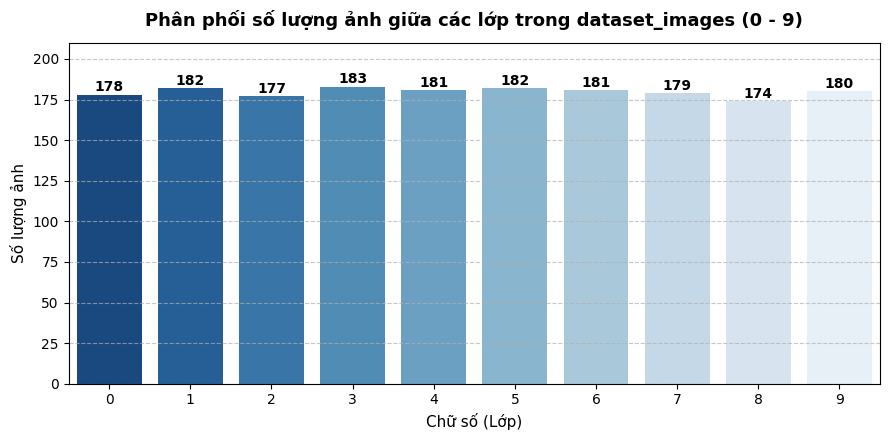

In [3]:
# Phân tích thống kê biến mục tiêu (Label)
label_series = pd.Series(y_all)
label_counts = label_series.value_counts().sort_index()
label_percent = (label_counts / len(y_all)) * 100

dist_df = pd.DataFrame({
    'Số lượng ảnh': label_counts,
    'Tỉ lệ (%)': label_percent.round(2)
})
print("Bảng phân phối số lượng ảnh theo từng lớp (0 - 9):")
display(dist_df)

# Trực quan hóa phân phối biến mục tiêu
plt.figure(figsize=(9, 4.5))
sns.barplot(x=dist_df.index, y=dist_df['Số lượng ảnh'], palette='Blues_r')
plt.title('Phân phối số lượng ảnh giữa các lớp trong dataset_images (0 - 9)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Chữ số (Lớp)', fontsize=11)
plt.ylabel('Số lượng ảnh', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(dist_df['Số lượng ảnh']):
    plt.text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.ylim(0, 210)
plt.tight_layout()
plt.show()


**Nhận xét về phân phối dữ liệu:**
- Tổng số lượng mẫu nạp từ thư mục `dataset_images` là **1.797 ảnh**, mỗi chữ số có từ **174 đến 183 ảnh** (khoảng $9.68\% - 10.18\%$ trên mỗi lớp).
- Phân phối giữa 10 lớp rất **cân bằng** (balanced dataset). Do đó, chỉ số Accuracy hoàn toàn có thể được dùng làm một độ đo chính thống, nhưng cần kết hợp thêm Macro Precision, Recall, F1-score và Confusion Matrix để đảm bảo không bỏ sót sai lệch của bất kỳ lớp nào.


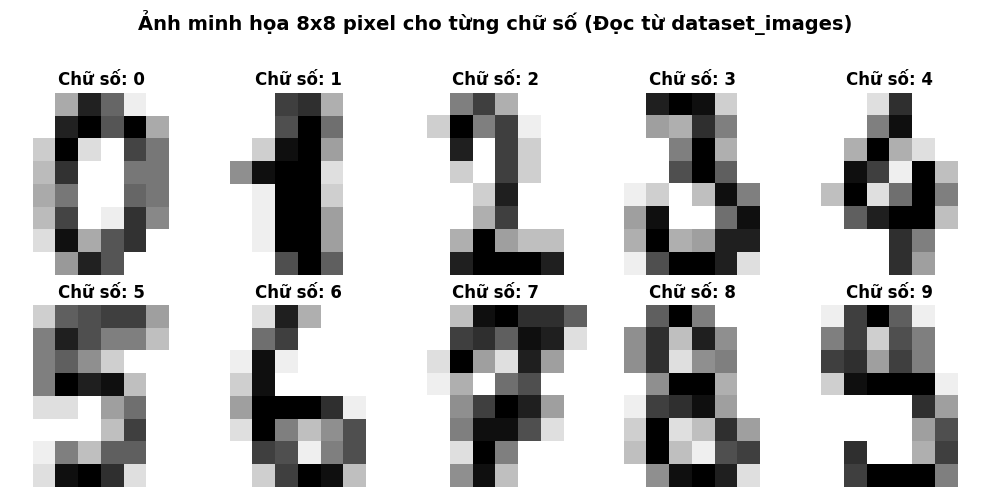

In [4]:
# Trực quan hóa ảnh mẫu của từng chữ số từ 0 đến 9
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    idx = np.where(y_all == i)[0][0]
    img = X_raw[idx].reshape(8, 8)
    ax.imshow(img, cmap='gray_r', interpolation='nearest')
    ax.set_title(f'Chữ số: {i}', fontsize=12, fontweight='bold')
    ax.axis('off')
plt.suptitle('Ảnh minh họa 8x8 pixel cho từng chữ số (Đọc từ dataset_images)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


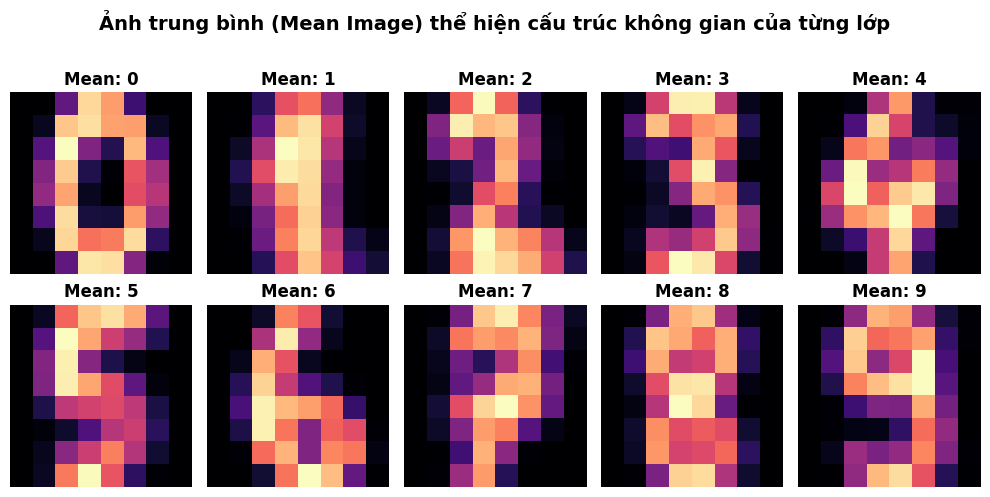

In [5]:
# Trực quan hóa ảnh trung bình (Mean Image) cho từng lớp chữ số
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    mean_img = X_raw[y_all == i].mean(axis=0).reshape(8, 8)
    ax.imshow(mean_img, cmap='magma', interpolation='nearest')
    ax.set_title(f'Mean: {i}', fontsize=12, fontweight='bold')
    ax.axis('off')
plt.suptitle('Ảnh trung bình (Mean Image) thể hiện cấu trúc không gian của từng lớp', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


**Nhận xét từ ảnh trung bình:**
- Các chữ số có đường nét rõ rệt tập trung vào trung tâm hình ảnh: Chữ số 0 có một vòng tròn rỗng ở giữa; chữ số 1 là một dải thẳng đứng hẹp; chữ số 8 có hai vòng khép kín.
- Một số chữ số có vùng sáng trùng lặp nhau đáng kể (ví dụ chữ số 3 và 8, hoặc chữ số 1 và 7), đây là manh mối ban đầu giải thích tại sao mô hình có thể bị nhầm lẫn ở các cặp số này khi độ phân giải chỉ vỏn vẹn $8 \times 8$.


---
## 3. Tiền xử lý dữ liệu (Preprocessing)

### 3.1 Chuẩn hóa cường độ pixel
- Giá trị pixel ảnh thô nằm trong đoạn $[0, 255]$. 
- Chuẩn hóa: Chúng ta chia toàn bộ giá trị cho $255.0$ để đưa về đoạn chuẩn $[0, 1]$.
- **Ý nghĩa kỹ thuật:**
  1. Với **K-NN**: Thuật toán dựa trên khoảng cách hình học ($L_2$ Euclidean hoặc $L_1$ Manhattan). Khi các pixel có cùng thang đo $[0, 1]$, khoảng cách giữa các điểm dữ liệu sẽ không bị thiên lệch bởi một vài pixel có biên độ quá lớn.
  2. Ổn định tính toán và tăng tốc hội tụ cho các thuật toán tối ưu hóa.

### 3.2 Tách tập huấn luyện và kiểm thử (Train/Test Split)
- Tỉ lệ: **80% Huấn luyện (Train)** và **20% Kiểm thử (Test)**.
- Sử dụng `stratify=y_all` để đảm bảo tỉ lệ phân phối của 10 lớp được giữ nguyên chính xác ở cả tập Train và Test.
- Cố định `random_state=42` để đảm bảo tính tái lập (reproducibility).
- **Hạn chế rò rỉ dữ liệu (Data Leakage):** Mọi phép biến đổi học tham số (như PCA) đều chỉ được fit trên tập Train và áp dụng (transform) sang tập Test.


In [6]:
# Chuẩn hóa về [0, 1] qua phép chia 255.0
X_norm = X_raw / 255.0

# Phân chia tập Train / Test với stratify và random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X_norm, y_all, test_size=0.20, random_state=42, stratify=y_all
)

print(f"Kích thước tập Huấn luyện (Train set): {X_train.shape[0]} mẫu ({X_train.shape[0]/len(X_norm)*100:.1f}%)")
print(f"Kích thước tập Kiểm thử (Test set):   {X_test.shape[0]} mẫu ({X_test.shape[0]/len(X_norm)*100:.1f}%)")
print(f"Số lượng đặc trưng đầu vào:           {X_train.shape[1]} pixels")

# Kiểm tra phân phối nhãn trên cả hai tập
split_check = pd.DataFrame({
    'Train Count': pd.Series(y_train).value_counts().sort_index(),
    'Test Count': pd.Series(y_test).value_counts().sort_index(),
    'Train Tỉ lệ (%)': (pd.Series(y_train).value_counts().sort_index() / len(y_train) * 100).round(2),
    'Test Tỉ lệ (%)': (pd.Series(y_test).value_counts().sort_index() / len(y_test) * 100).round(2)
})
display(split_check)


Kích thước tập Huấn luyện (Train set): 1437 mẫu (80.0%)
Kích thước tập Kiểm thử (Test set):   360 mẫu (20.0%)
Số lượng đặc trưng đầu vào:           64 pixels


,Train Count,Test Count,Train Tỉ lệ (%),Test Tỉ lệ (%)
0,142,36,9.88,10.00
1,146,36,10.16,10.00
2,142,35,9.88,9.72
3,146,37,10.16,10.28
4,145,36,10.09,10.00
5,145,37,10.09,10.28
6,145,36,10.09,10.00
7,143,36,9.95,10.00
8,139,35,9.67,9.72
9,144,36,10.02,10.00


---
## 4. Biểu diễn và trích xuất đặc trưng (Feature Representation)

Để kiểm chứng tác động của phương pháp biểu diễn dữ liệu tới mô hình học máy (yêu cầu cốt lõi của Rubric), nhóm triển khai và so sánh **3 phương án biểu diễn đặc trưng**:

1. **Phương án 1 (Baseline - Raw Pixels):** Vector phẳng 64 chiều biểu thị trực tiếp cường độ pixel sau chuẩn hóa $[0, 1]$.
2. **Phương án 2 (HOG - Histogram of Oriented Gradients):**
   - Trích xuất thông tin hướng và độ lớn của gradient cục bộ, giúp mô tả hình dạng đường biên của nét chữ viết tay.
   - Tham số: `orientations=8`, `pixels_per_cell=(2, 2)`, `cells_per_block=(1, 1)` $\rightarrow$ tạo ra vector đặc trưng 128 chiều.
3. **Phương án 3 (PCA - Principal Component Analysis):**
   - Giảm số chiều không gian đặc trưng bằng phép chiếu tuyến tính trực giao lên các trục phương sai lớn nhất.
   - Tiêu chí lựa chọn: Giữ lại $\ge 95\%$ tổng phương sai tích lũy của tập huấn luyện.


In [7]:
# 1. Trích xuất đặc trưng HOG
print("Đang trích xuất đặc trưng HOG...")
X_train_hog = np.array([
    hog(img.reshape(8, 8), orientations=8, pixels_per_cell=(2, 2), cells_per_block=(1, 1))
    for img in X_train
])
X_test_hog = np.array([
    hog(img.reshape(8, 8), orientations=8, pixels_per_cell=(2, 2), cells_per_block=(1, 1))
    for img in X_test
])
print(f"Kích thước đặc trưng HOG: {X_train_hog.shape[1]} chiều.")

# 2. Áp dụng PCA (Fit ONLY trên tập Train để tránh Data Leakage)
print("Đang huấn luyện PCA...")
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
n_pca = X_train_pca.shape[1]
print(f"Kích thước đặc trưng PCA: {n_pca} thành phần chính (giữ {pca.explained_variance_ratio_.sum()*100:.2f}% phương sai).")


Đang trích xuất đặc trưng HOG...


Kích thước đặc trưng HOG: 128 chiều.
Đang huấn luyện PCA...
Kích thước đặc trưng PCA: 28 thành phần chính (giữ 95.03% phương sai).


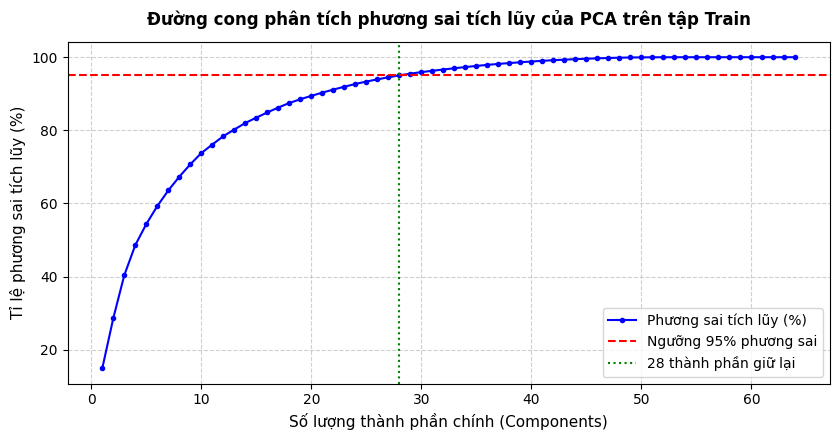

In [8]:
# Trực quan hóa đường cong phương sai tích lũy PCA
pca_full = PCA().fit(X_train)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_) * 100

plt.figure(figsize=(8.5, 4.5))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, 'b-o', markersize=3, label='Phương sai tích lũy (%)')
plt.axhline(y=95, color='r', linestyle='--', label='Ngưỡng 95% phương sai')
plt.axvline(x=n_pca, color='g', linestyle=':', label=f'{n_pca} thành phần giữ lại')
plt.title('Đường cong phân tích phương sai tích lũy của PCA trên tập Train', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Số lượng thành phần chính (Components)', fontsize=11)
plt.ylabel('Tỉ lệ phương sai tích lũy (%)', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


**Bảng so sánh 3 phương pháp biểu diễn đặc trưng:**

| Phương pháp biểu diễn | Số chiều đặc trưng | Ý nghĩa vật lý / toán học | Ưu điểm / Nhược điểm dự kiến |
|---|---|---|---|
| **Raw Pixels (Baseline)** | 64 | Cường độ sáng từng pixel ($8 \times 8$) | Giữ toàn bộ thông tin gốc, nhạy cảm với dịch chuyển |
| **HOG Features** | 128 | Phân phối hướng gradient vi phân | Tốt cho ảnh lớn; có thể mất chi tiết trên ảnh $8 \times 8$ |
| **PCA Components** | 28 | Hình chiếu trên 28 trục phương sai cực đại | Giảm $56.25\%$ số chiều, khử nhiễu, tăng tốc tính toán |


---
## 5. Huấn luyện mô hình và tinh chỉnh siêu tham số

Theo quy định hướng dẫn bài tập lớn, nhóm thực hiện:
- **Baseline mốc so sánh:** K-NN với $k=1$, metric Euclidean trên Raw Pixels mặc định.
- **Mô hình 1: K-Nearest Neighbors (K-NN):**
  - Tinh chỉnh tham số $k \in [1, 3, 5, 7, 9, 11, 15]$.
  - Tinh chỉnh metric khoảng cách: `euclidean` ($L_2$) và `manhattan` ($L_1$).
  - Đánh giá chéo 5-Fold Stratified Cross-Validation để đo tính khái quát hóa ($Mean \pm Std$).
- **Mô hình 2: Cây quyết định (Decision Tree):**
  - Tinh chỉnh độ sâu tối đa `max_depth` $\in [3, 5, 8, 10, 15, \text{None}]$.
  - Tinh chỉnh tiêu chí phân chia `criterion`: `gini` và `entropy`.
  - Phân tích hiện tượng quá khớp (Overfitting) khi cây phát triển tự do.
- **Thực nghiệm chéo:** Huấn luyện cả hai thuật toán trên cả 3 tập đặc trưng (Raw Pixels, HOG, PCA).


In [9]:
# Thiết lập hàm đánh giá thống nhất có đo thời gian huấn luyện và 5-fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
all_results = []

def run_experiment(name, model, X_tr, X_te, y_tr, y_te, feat_name, params_str):
    # 5-Fold CV chỉ trên tập Train -> dùng để CHỌN siêu tham số (không đụng tới tập Test)
    cv_scores = cross_validate(model, X_tr, y_tr, cv=cv, scoring=['accuracy', 'f1_macro'], n_jobs=1)

    # Huấn luyện trên toàn bộ train set (đo thời gian fit) và đánh giá trên test set
    t0 = time.perf_counter()
    model.fit(X_tr, y_tr)
    train_time_ms = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter()
    y_pred = model.predict(X_te)
    predict_time_ms = (time.perf_counter() - t0) * 1000
    
    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, average='macro')
    rec = recall_score(y_te, y_pred, average='macro')
    f1 = f1_score(y_te, y_pred, average='macro')
    
    result = {
        'Mô hình': name,
        'Đặc trưng': feat_name,
        'Tham số': params_str,
        'CV Accuracy': f"{cv_scores['test_accuracy'].mean():.4f} ± {cv_scores['test_accuracy'].std():.4f}",
        'CV F1-Macro': f"{cv_scores['test_f1_macro'].mean():.4f} ± {cv_scores['test_f1_macro'].std():.4f}",
        'Test Accuracy': acc,
        'Test Precision': prec,
        'Test Recall': rec,
        'Test F1-Macro': f1,
        'Train Time (ms)': round(train_time_ms, 2),
        'Predict Time (ms)': round(predict_time_ms, 2),
        '_cv_acc': cv_scores['test_accuracy'].mean(),
        '_model': model,
        '_preds': y_pred
    }
    all_results.append(result)
    return result


In [10]:
# 1. Baseline: K-NN (k=1, Euclidean) trên Raw Pixels
baseline_model = KNeighborsClassifier(n_neighbors=1, metric='euclidean')
res_base = run_experiment('Baseline: K-NN', baseline_model, X_train, X_test, y_train, y_test, 'Raw Pixels', 'k=1, metric=euclidean')
print(f"Baseline Accuracy trên tập Test: {res_base['Test Accuracy']:.4f}")


Baseline Accuracy trên tập Test: 0.9778


K-NN tốt nhất theo 5-Fold CV: k=3, metric=euclidean (CV accuracy = 0.9903)


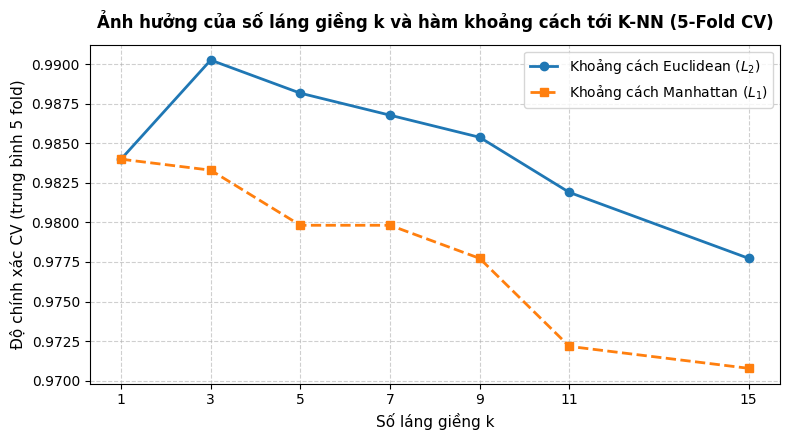

In [11]:
# 2. Thử nghiệm và Tinh chỉnh siêu tham số K-NN trên Raw Pixels
k_list = [1, 3, 5, 7, 9, 11, 15]
knn_cv = {}  # (k, metric) -> CV accuracy trên tập Train

for k in k_list:
    for metric in ['euclidean', 'manhattan']:
        m = KNeighborsClassifier(n_neighbors=k, metric=metric)
        r = run_experiment('K-NN', m, X_train, X_test, y_train, y_test, 'Raw Pixels', f'k={k}, metric={metric}')
        knn_cv[(k, metric)] = r['_cv_acc']

# Chọn tham số tốt nhất theo CV accuracy (KHÔNG dùng tập Test để chọn -> tránh rò rỉ dữ liệu)
best_k, best_metric = max(knn_cv, key=knn_cv.get)
print(f"K-NN tốt nhất theo 5-Fold CV: k={best_k}, metric={best_metric} (CV accuracy = {knn_cv[(best_k, best_metric)]:.4f})")

# Vẽ biểu đồ CV Accuracy theo k
plt.figure(figsize=(8, 4.5))
plt.plot(k_list, [knn_cv[(k, 'euclidean')] for k in k_list], 'o-', color='#1f77b4', linewidth=2, label='Khoảng cách Euclidean ($L_2$)')
plt.plot(k_list, [knn_cv[(k, 'manhattan')] for k in k_list], 's--', color='#ff7f0e', linewidth=2, label='Khoảng cách Manhattan ($L_1$)')
plt.title('Ảnh hưởng của số láng giềng k và hàm khoảng cách tới K-NN (5-Fold CV)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Số láng giềng k', fontsize=11)
plt.ylabel('Độ chính xác CV (trung bình 5 fold)', fontsize=11)
plt.xticks(k_list)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


In [12]:
# 3. K-NN trên HOG và PCA
# K-NN trên HOG
knn_hog = KNeighborsClassifier(n_neighbors=best_k, metric=best_metric)
run_experiment('K-NN', knn_hog, X_train_hog, X_test_hog, y_train, y_test, 'HOG (128)', f'k={best_k}, metric={best_metric}')

# K-NN trên PCA
knn_pca = KNeighborsClassifier(n_neighbors=best_k, metric=best_metric)
run_experiment('K-NN', knn_pca, X_train_pca, X_test_pca, y_train, y_test, f'PCA ({n_pca})', f'k={best_k}, metric={best_metric}')
print("Đã hoàn thành thử nghiệm K-NN trên HOG và PCA.")


Đã hoàn thành thử nghiệm K-NN trên HOG và PCA.


Cây quyết định tốt nhất theo 5-Fold CV: max_depth=10, criterion=gini (CV accuracy = 0.8504)
Cây không giới hạn độ sâu (gini): Train accuracy = 1.0000


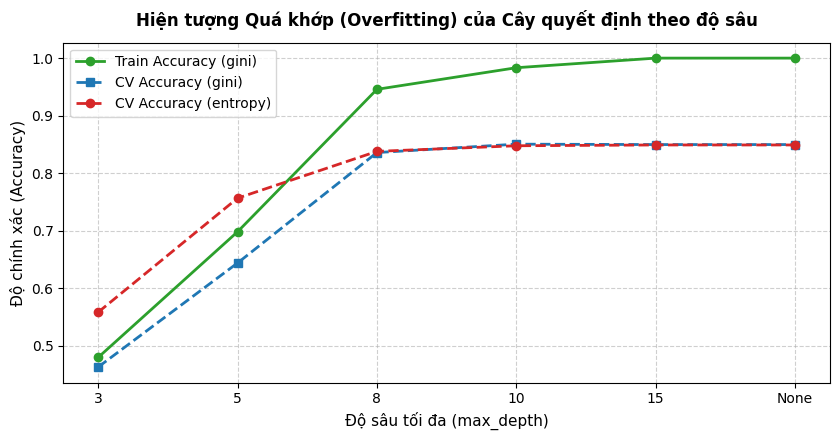

In [13]:
# 4. Thử nghiệm và Tinh chỉnh siêu tham số Cây quyết định (Decision Tree)
depth_list = [3, 5, 8, 10, 15, None]
dt_cv, dt_train = {}, {}  # (depth, criterion) -> accuracy

for crit in ['gini', 'entropy']:
    for d in depth_list:
        dt = DecisionTreeClassifier(max_depth=d, criterion=crit, random_state=42)
        r = run_experiment('Decision Tree', dt, X_train, X_test, y_train, y_test, 'Raw Pixels', f'depth={d}, crit={crit}')
        dt_cv[(d, crit)] = r['_cv_acc']
        dt_train[(d, crit)] = accuracy_score(y_train, dt.predict(X_train))

best_depth, best_crit = max(dt_cv, key=dt_cv.get)
print(f"Cây quyết định tốt nhất theo 5-Fold CV: max_depth={best_depth}, criterion={best_crit} (CV accuracy = {dt_cv[(best_depth, best_crit)]:.4f})")
print(f"Cây không giới hạn độ sâu ({best_crit}): Train accuracy = {dt_train[(None, best_crit)]:.4f}")

# Vẽ biểu đồ Overfitting của Decision Tree: Train vs CV (validation)
plt.figure(figsize=(8.5, 4.5))
depth_str = [str(d) for d in depth_list]
plt.plot(depth_str, [dt_train[(d, best_crit)] for d in depth_list], 'o-', color='#2ca02c', linewidth=2, label=f'Train Accuracy ({best_crit})')
plt.plot(depth_str, [dt_cv[(d, 'gini')] for d in depth_list], 's--', color='#1f77b4', linewidth=2, label='CV Accuracy (gini)')
plt.plot(depth_str, [dt_cv[(d, 'entropy')] for d in depth_list], 'o--', color='#d62728', linewidth=2, label='CV Accuracy (entropy)')
plt.title('Hiện tượng Quá khớp (Overfitting) của Cây quyết định theo độ sâu', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Độ sâu tối đa (max_depth)', fontsize=11)
plt.ylabel('Độ chính xác (Accuracy)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


In [14]:
# 5. Decision Tree trên HOG và PCA
dt_hog = DecisionTreeClassifier(max_depth=best_depth, criterion=best_crit, random_state=42)
run_experiment('Decision Tree', dt_hog, X_train_hog, X_test_hog, y_train, y_test, 'HOG (128)', f'depth={best_depth}, crit={best_crit}')

dt_pca = DecisionTreeClassifier(max_depth=best_depth, criterion=best_crit, random_state=42)
run_experiment('Decision Tree', dt_pca, X_train_pca, X_test_pca, y_train, y_test, f'PCA ({n_pca})', f'depth={best_depth}, crit={best_crit}')
print("Đã hoàn thành thử nghiệm Cây quyết định trên HOG và PCA.")


Đã hoàn thành thử nghiệm Cây quyết định trên HOG và PCA.


---
## 6. Đánh giá và so sánh kết quả thực nghiệm

Dưới đây là bảng tổng hợp tất cả các thử nghiệm học máy đã thực hiện, so sánh chi tiết:
- Độ chính xác đánh giá chéo 5-Fold ($Mean \pm Std$)
- Độ chính xác tập kiểm thử (Test Accuracy)
- Macro Precision, Recall, F1-score
- Thời gian huấn luyện (Train Time)


In [15]:
# Bảng tổng hợp so sánh tất cả các phương án
results_table = pd.DataFrame(all_results).drop(columns=['_cv_acc', '_model', '_preds'])
results_table['Test Accuracy (%)'] = (results_table['Test Accuracy'] * 100).round(2)
results_table['Test F1-Macro (%)'] = (results_table['Test F1-Macro'] * 100).round(2)
display(results_table)


,Mô hình,Đặc trưng,Tham số,CV Accuracy,CV F1-Macro,Test Accuracy,Test Precision,Test Recall,Test F1-Macro,Train Time (ms),Predict Time (ms),Test Accuracy (%),Test F1-Macro (%)
0,Baseline: K-NN,Raw Pixels,"k=1, metric=euclidean",0.9840 ± 0.0028,0.9840 ± 0.0029,0.977778,0.979466,0.977535,0.977587,0.58,19.21,97.78,97.76
1,K-NN,Raw Pixels,"k=1, metric=euclidean",0.9840 ± 0.0028,0.9840 ± 0.0029,0.977778,0.979466,0.977535,0.977587,0.81,22.98,97.78,97.76
2,K-NN,Raw Pixels,"k=1, metric=manhattan",0.9840 ± 0.0042,0.9840 ± 0.0042,0.969444,0.971482,0.969043,0.968940,0.52,35.42,96.94,96.89
3,K-NN,Raw Pixels,"k=3, metric=euclidean",0.9903 ± 0.0034,0.9902 ± 0.0034,0.972222,0.974359,0.971976,0.972034,0.53,18.81,97.22,97.20
4,K-NN,Raw Pixels,"k=3, metric=manhattan",0.9833 ± 0.0060,0.9832 ± 0.0061,0.963889,0.966264,0.963642,0.963646,1.37,42.30,96.39,96.36
5,K-NN,Raw Pixels,"k=5, metric=euclidean",0.9882 ± 0.0052,0.9881 ± 0.0052,0.969444,0.972399,0.969277,0.969535,0.53,17.82,96.94,96.95
6,K-NN,Raw Pixels,"k=5, metric=manhattan",0.9798 ± 0.0051,0.9797 ± 0.0052,0.961111,0.964703,0.960864,0.960984,0.56,33.62,96.11,96.10
7,K-NN,Raw Pixels,"k=7, metric=euclidean",0.9868 ± 0.0041,0.9867 ± 0.0041,0.963889,0.966396,0.963717,0.963765,0.50,16.63,96.39,96.38
8,K-NN,Raw Pixels,"k=7, metric=manhattan",0.9798 ± 0.0071,0.9797 ± 0.0072,0.966667,0.970204,0.966420,0.966673,0.74,32.85,96.67,96.67
9,K-NN,Raw Pixels,"k=9, metric=euclidean",0.9854 ± 0.0060,0.9852 ± 0.0061,0.966667,0.969271,0.966499,0.966642,0.63,25.12,96.67,96.66


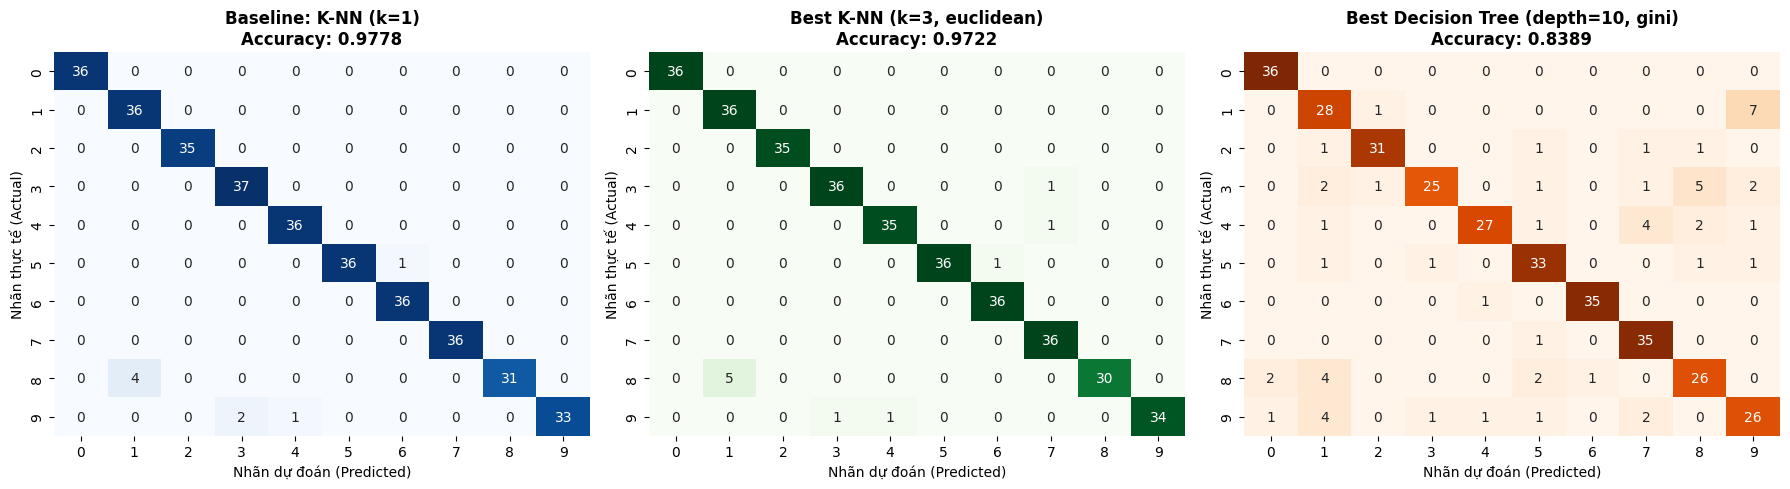

In [16]:
# Lựa chọn 3 mô hình tiêu biểu để so sánh chuyên sâu
# 1. Baseline: K-NN (k=1)
# 2. Best K-NN trên Raw Pixels (tham số chọn theo 5-Fold CV)
# 3. Best Decision Tree trên Raw Pixels (tham số chọn theo 5-Fold CV)

best_knn = KNeighborsClassifier(n_neighbors=best_k, metric=best_metric).fit(X_train, y_train)
best_dt = DecisionTreeClassifier(max_depth=best_depth, criterion=best_crit, random_state=42).fit(X_train, y_train)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Baseline K-NN
cm_base = confusion_matrix(y_test, baseline_model.predict(X_test))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f'Baseline: K-NN (k=1)\nAccuracy: {accuracy_score(y_test, baseline_model.predict(X_test)):.4f}', fontweight='bold')
axes[0].set_xlabel('Nhãn dự đoán (Predicted)')
axes[0].set_ylabel('Nhãn thực tế (Actual)')

# Best K-NN
cm_knn = confusion_matrix(y_test, best_knn.predict(X_test))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title(f'Best K-NN (k={best_k}, {best_metric})\nAccuracy: {accuracy_score(y_test, best_knn.predict(X_test)):.4f}', fontweight='bold')
axes[1].set_xlabel('Nhãn dự đoán (Predicted)')
axes[1].set_ylabel('Nhãn thực tế (Actual)')

# Best Decision Tree
cm_dt = confusion_matrix(y_test, best_dt.predict(X_test))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Oranges', ax=axes[2], cbar=False)
axes[2].set_title(f'Best Decision Tree (depth={best_depth}, {best_crit})\nAccuracy: {accuracy_score(y_test, best_dt.predict(X_test)):.4f}', fontweight='bold')
axes[2].set_xlabel('Nhãn dự đoán (Predicted)')
axes[2].set_ylabel('Nhãn thực tế (Actual)')

plt.tight_layout()
plt.show()


In [17]:
# Báo cáo phân loại chi tiết (Classification Report) của Best K-NN
print("=== BÁO CÁO PHÂN LOẠI CHI TIẾT CỦA MÔ HÌNH TỐT NHẤT (BEST K-NN) ===")
print(classification_report(y_test, best_knn.predict(X_test), digits=4))


=== BÁO CÁO PHÂN LOẠI CHI TIẾT CỦA MÔ HÌNH TỐT NHẤT (BEST K-NN) ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.8780    1.0000    0.9351        36
           2     1.0000    1.0000    1.0000        35
           3     0.9730    0.9730    0.9730        37
           4     0.9722    0.9722    0.9722        36
           5     1.0000    0.9730    0.9863        37
           6     0.9730    1.0000    0.9863        36
           7     0.9474    1.0000    0.9730        36
           8     1.0000    0.8571    0.9231        35
           9     1.0000    0.9444    0.9714        36

    accuracy                         0.9722       360
   macro avg     0.9744    0.9720    0.9720       360
weighted avg     0.9743    0.9722    0.9721       360



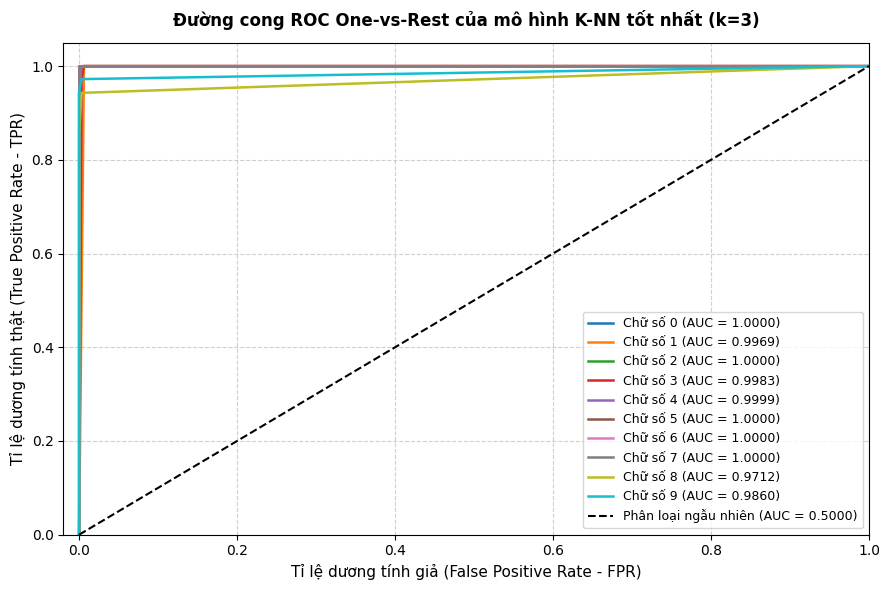

In [18]:
# Vẽ đường cong ROC One-vs-Rest cho tất cả 10 lớp của Best K-NN
y_test_bin = label_binarize(y_test, classes=range(10))
y_prob_knn = best_knn.predict_proba(X_test)

plt.figure(figsize=(9, 6))
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for i in range(10):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_knn[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=1.8, label=f'Chữ số {i} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Phân loại ngẫu nhiên (AUC = 0.5000)')
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỉ lệ dương tính giả (False Positive Rate - FPR)', fontsize=11)
plt.ylabel('Tỉ lệ dương tính thật (True Positive Rate - TPR)', fontsize=11)
plt.title(f'Đường cong ROC One-vs-Rest của mô hình K-NN tốt nhất (k={best_k})', fontsize=12, fontweight='bold', pad=12)
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


---
## 7. Phân tích lỗi chuyên sâu (Error Analysis)

Đây là phần trọng tâm giúp hiểu rõ bản chất mô hình và nguyên nhân sai lệch:
1. **Xác định các mẫu bị dự đoán sai:** Trích xuất các trường hợp trên tập Test mà mô hình K-NN tốt nhất đưa ra kết quả không chính xác.
2. **Trực quan hóa hình ảnh thực tế:** Quan sát nét chữ viết tay cụ thể gây nhầm lẫn.
3. **Phân tích hình học và độ phân giải:** Lý giải vì sao mẫu đó lại gần với lớp sai trong không gian đặc trưng.


Tổng số mẫu dự đoán sai trên tập Test: 10 / 360 mẫu.
Tỉ lệ sai sót: 2.78%
Các cặp nhầm lẫn (thực tế -> dự đoán):
8 -> 1    5
9 -> 3    1
3 -> 7    1
5 -> 6    1
9 -> 4    1
4 -> 7    1


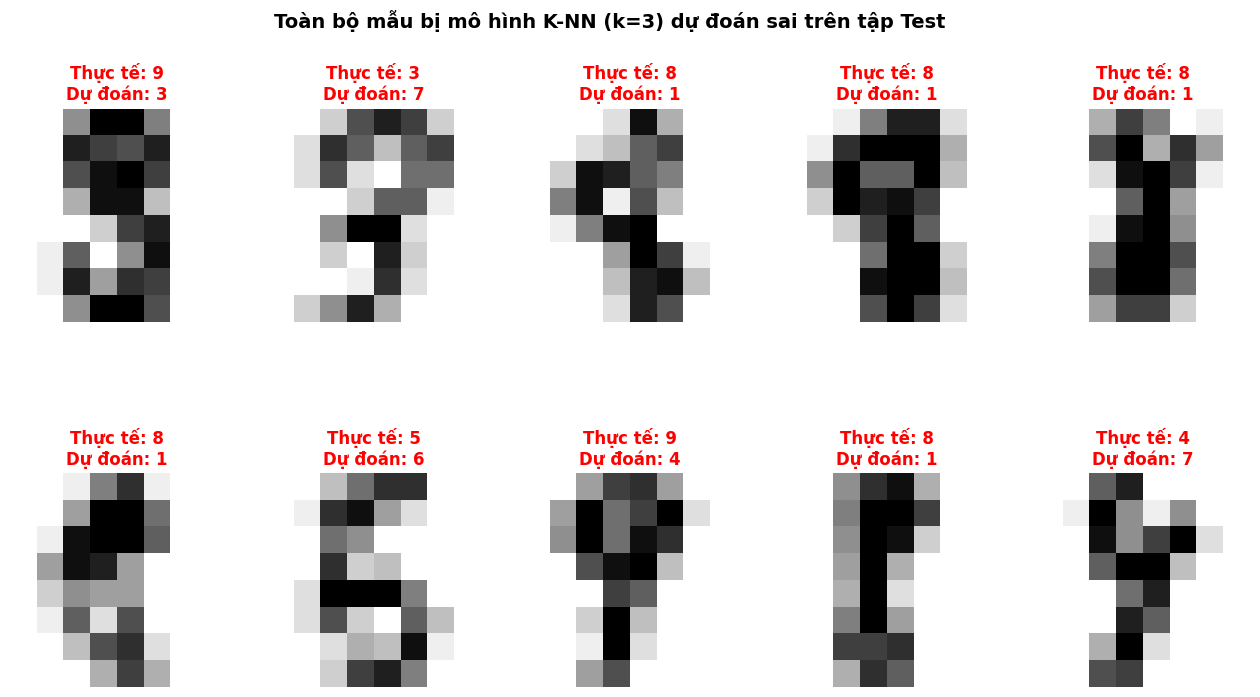

In [19]:
# Trích xuất và trực quan hóa các mẫu bị dự đoán sai bởi Best K-NN
preds_knn = best_knn.predict(X_test)
mis_indices = np.where(preds_knn != y_test)[0]

print(f"Tổng số mẫu dự đoán sai trên tập Test: {len(mis_indices)} / {len(y_test)} mẫu.")
print(f"Tỉ lệ sai sót: {len(mis_indices)/len(y_test)*100:.2f}%")

# Thống kê các cặp nhầm lẫn (thực tế -> dự đoán)
pairs = pd.Series([f"{t} -> {p}" for t, p in zip(y_test[mis_indices], preds_knn[mis_indices])]).value_counts()
print("Các cặp nhầm lẫn (thực tế -> dự đoán):")
print(pairs.to_string())

if len(mis_indices) > 0:
    n_cols = min(len(mis_indices), 5)
    n_rows = int(np.ceil(len(mis_indices) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 4.0 * n_rows), squeeze=False,
                             gridspec_kw={'hspace': 0.45})
    for ax in axes.flat:
        ax.axis('off')
    for ax, idx in zip(axes.flat, mis_indices):
        ax.imshow(X_test[idx].reshape(8, 8), cmap='gray_r', interpolation='nearest')
        ax.set_title(f'Thực tế: {y_test[idx]}\nDự đoán: {preds_knn[idx]}', fontsize=12, color='red', fontweight='bold')
    plt.suptitle(f'Toàn bộ mẫu bị mô hình K-NN (k={best_k}) dự đoán sai trên tập Test', fontsize=14, fontweight='bold')
    plt.show()


### Nhận xét và giả thuyết nguyên nhân gây lỗi
Mô hình K-NN tốt nhất sai **10/360 mẫu (2,78%)**. Lỗi tập trung rất rõ:
- **8 → 1 (5/10 lỗi):** đây là cặp nhầm lẫn chiếm một nửa tổng số lỗi. Các mẫu số 8 bị nhầm đều có nét mảnh, hai vòng tròn bị "bóp" hẹp theo chiều ngang nên sau khi thu về $8 \times 8$ chỉ còn một dải sáng thẳng đứng ở giữa – rất giống hình thái của số 1 (xem ảnh trung bình ở Phần 2). Với khoảng cách Euclid, các pixel trống hai bên mép đóng góp ít, nên láng giềng gần nhất là các mẫu số 1.
- **3 → 7, 4 → 7, 9 → 3, 9 → 4, 5 → 6 (mỗi cặp 1 lỗi):** các mẫu có nét viết lệch/thiếu nét (vd. số 9 có vòng trên hở giống số 4, số 5 có nét dưới khép kín giống số 6).

**Nguyên nhân chung:**
1. **Độ phân giải $8 \times 8$:** khe hở và vòng khép kín – chi tiết phân biệt 8/1, 9/4, 5/6 – bị mất khi gộp khối $4 \times 4$ pixel.
2. **K-NN so khớp theo cường độ pixel tuyệt đối:** không bất biến với độ dày nét và dịch chuyển nhỏ, nên một mẫu viết mảnh/lệch có thể gần các mẫu lớp khác hơn.
3. **Khuyến nghị cải thiện:** thêm đặc trưng bất biến hình dạng (vd. HOG với cell lớn hơn trên ảnh gốc độ phân giải cao), tăng cường dữ liệu bằng dịch chuyển/co giãn nét, hoặc dùng dữ liệu độ phân giải cao hơn (MNIST $28 \times 28$).


---
## 8. Thảo luận, Khuyến nghị và Kết luận

### 8.1 So sánh ưu nhược điểm giữa K-NN và Cây quyết định
- **K-Nearest Neighbors (K-NN):**
  - **Ưu điểm:** Đạt độ chính xác cao (CV $99{,}03\%$, Test $97{,}22\%$, F1-macro $97{,}20\%$ với $k=3$, Euclid). Khoảng cách Euclid/Manhattan đo độ tương đồng đồng thời trên toàn bộ 64 pixel – phù hợp với dữ liệu đã được căn giữa, chuẩn hóa kích thước như `load_digits`.
  - **Baseline ($k=1$):** Test $97{,}78\%$ – cao hơn $k=3$ trên tập Test nhưng thấp hơn trên CV ($98{,}40\%$ so với $99{,}03\%$). Vì tiêu chí chọn là CV (tránh chọn theo tập Test), nhóm giữ $k=3$; chênh lệch 0,56\% trên Test tương ứng 2 mẫu/360, nằm trong dao động ngẫu nhiên.
  - **Nhược điểm:** Chi phí tính toán ở giai đoạn dự đoán (Inference) lớn vì phải tính khoảng cách tới toàn bộ tập huấn luyện ($O(N \times D)$); tốn bộ nhớ lưu trữ tập dữ liệu học.
- **Cây quyết định (Decision Tree):**
  - **Ưu điểm:** Tốc độ dự đoán cực nhanh (chỉ qua vài phép so sánh điều kiện $O(\text{depth})$); mô hình dạng luật, dễ giải thích trực quan.
  - **Nhược điểm:** Độ chính xác thấp hơn rõ rệt: cây tốt nhất (max_depth=10, gini) đạt CV $85{,}04\%$, Test $83{,}89\%$. Phép tách trực giao (axis-aligned split) trên từng pixel độc lập không nắm bắt được quan hệ giữa các pixel lân cận (nét chéo, đường cong). Khi không giới hạn độ sâu, Train accuracy đạt $100\%$ nhưng CV dừng ở $\approx 85\%$ – minh chứng **quá khớp (overfitting)**. Gini và entropy cho kết quả tương đương ở độ sâu $\ge 8$.

### 8.2 Ảnh hưởng của phương pháp biểu diễn đặc trưng
- **Raw Pixels (baseline biểu diễn):** tốt nhất với K-NN (Test $97{,}22\%$) vì ảnh $8 \times 8$ đã được căn giữa và chuẩn hóa sẵn – mỗi pixel đều mang thông tin.
- **HOG:** K-NN giảm còn Test $91{,}94\%$. HOG được thiết kế cho ảnh lớn; trên ảnh $8 \times 8$, mỗi cell $2 \times 2$ chỉ có 4 pixel nên histogram hướng gradient rất nhiễu và mất thông tin cường độ tuyệt đối. Với Cây quyết định, HOG cũng kém hơn Raw (Test $77{,}78\%$ so với $83{,}89\%$).
- **PCA (28 thành phần, giữ $95{,}03\%$ phương sai):** giảm $56{,}25\%$ số chiều. Với K-NN, Test $97{,}50\%$ (hơn Raw 1 mẫu) nhưng CV thấp hơn một chút ($98{,}89\%$ so với $99{,}03\%$). Với Cây quyết định, PCA cao hơn Raw trên Test ($85{,}83\%$ so với $83{,}89\%$) nhưng thấp hơn trên CV ($82{,}47\%$ so với $85{,}04\%$). Hai tiêu chí cho kết luận ngược nhau và chênh lệch nằm trong độ lệch chuẩn CV, nên PCA được đánh giá là **tương đương** Raw về độ chính xác.
- **Tốc độ:** K-NN huấn luyện gần như tức thì (chỉ lưu dữ liệu) nhưng dự đoán chậm hơn cây quyết định khoảng 30 lần (cột *Predict Time*). Về lý thuyết PCA giảm chi phí tính khoảng cách theo số chiều (64 → 28), nhưng trên tập dữ liệu nhỏ này thời gian dự đoán chỉ giảm nhẹ vì chi phí cố định của thư viện chiếm phần lớn.

### 8.3 Hạn chế của nghiên cứu
1. Kích thước dữ liệu còn nhỏ (1.797 mẫu) và độ phân giải hạn chế ($8 \times 8$).
2. Ảnh đã được tiền xử lý lý tưởng (căn giữa, không có nhiễu nền hoặc xoay nghiêng bất thường).
3. Chưa thử nghiệm các mô hình nơ-ron tích chập (CNN) hiện đại vốn là tiêu chuẩn vàng trong thị giác máy tính.

### 8.4 Hướng phát triển tiếp theo
1. Mở rộng thử nghiệm trên bộ dữ liệu chuẩn **MNIST** ($28 \times 28$ pixel, 70.000 mẫu).
2. Áp dụng kỹ thuật tăng cường dữ liệu (Data Augmentation: xoay nhẹ, tịnh tiến, thêm nhiễu Gaussian).
3. Triển khai mô hình K-NN kết hợp PCA lên vi điều khiển (nhúng IoT) để nhận diện số công tơ điện nước.


---
## 9. Xuất mô hình phục vụ triển khai Demo GUI

Để phục vụ ứng dụng Demo GUI (cộng điểm thưởng theo mục 2.4 của Hướng dẫn thực hiện bài tập lớn), chúng ta lưu mô hình K-NN tối ưu ($k=3$, metric Euclidean) đã huấn luyện trực tiếp trên tập ảnh `dataset_images/`:
- `best_model.pkl`: File mô hình chuẩn hóa, sẵn sàng nạp tức thì trong ứng dụng giao diện Tkinter `gui_demo.py`.


In [20]:
# Lưu mô hình tốt nhất
model_file = 'best_model.pkl'
joblib.dump(best_knn, model_file)

print(f"Đã lưu mô hình tốt nhất vào: {model_file}")
print("Mô hình đã sẵn sàng để khởi chạy giao diện GUI qua lệnh: python gui_demo.py")


Đã lưu mô hình tốt nhất vào: best_model.pkl
Mô hình đã sẵn sàng để khởi chạy giao diện GUI qua lệnh: python gui_demo.py
